One small linear program, solved four ways: by drawing it, by a simplex tableau you pivot by hand,
by a few steps of an interior-point method, and by Gurobi. All four should agree, and the point is
to see *how differently* they get there.

$$\begin{aligned} \max\ z = 2x_1 + 3x_2 \quad \text{s.t.}\quad -x_1 + x_2 &\le 5 \\ x_1 + 3x_2 &\le 35 \\ x_1 &\le 20 \\ x_1,\ x_2 &\ge 0 \end{aligned}$$

To run it yourself: `pip install gurobipy numpy pandas matplotlib`. The free licence that comes with
`pip install gurobipy` is enough for everything here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gurobipy as gp
from gurobipy import GRB

## The problem as data

Every method below starts from the same three pieces: the objective coefficients $c$, the
constraint matrix $A$ and the right-hand sides $b$.

In [2]:
c = np.array([2.0, 3.0])
A = np.array([[-1.0, 1.0],
              [ 1.0, 3.0],
              [ 1.0, 0.0]])
b = np.array([5.0, 35.0, 20.0])
print("A is", A.shape, "| b =", b, "| c =", c)

A is (3, 2) | b = [ 5. 35. 20.] | c = [2. 3.]


## Method 1: draw it

Each constraint is a line; the feasible region is the side of every line that satisfies it. The
dashed lines are the objective at three values of $z$. **Before you look at the next cell, predict:
which corner does the highest dashed line reach last?**

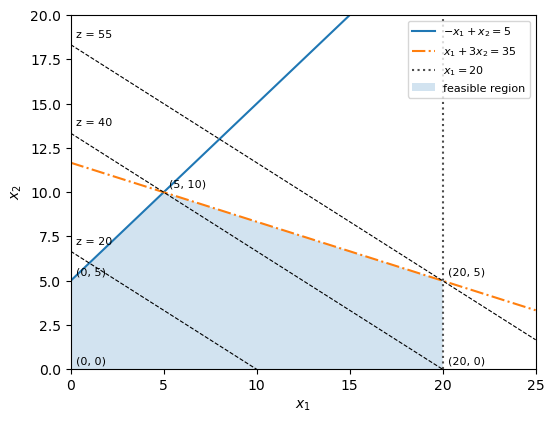

In [3]:
x1 = np.linspace(0, 25, 200)
fig, ax = plt.subplots(figsize=(6, 4.6))
ax.plot(x1, 5 + x1, label=r"$-x_1 + x_2 = 5$")
ax.plot(x1, (35 - x1) / 3, label=r"$x_1 + 3x_2 = 35$", linestyle="-.")
ax.axvline(20, color="0.3", label=r"$x_1 = 20$", linestyle=":")
corners = np.array([[0, 0], [20, 0], [20, 5], [5, 10], [0, 5]])
ax.fill(corners[:, 0], corners[:, 1], alpha=0.2, label="feasible region")
for z in (20, 40, 55):
    ax.plot(x1, (z - 2 * x1) / 3, "k--", linewidth=0.8)
    ax.annotate(f"z = {z}", (0.3, z / 3 + 0.4), fontsize=8)
for x, y in corners:
    ax.annotate(f"({x}, {y})", (x, y), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.set(xlim=(0, 25), ylim=(0, 20), xlabel="$x_1$", ylabel="$x_2$")
ax.legend(loc="upper right", fontsize=8)
plt.show()
# alt: The feasible region is a five-sided polygon with corners (0,0), (20,0), (20,5), (5,10) and (0,5); dashed objective lines at z = 20, 40 and 55 move up and to the right, and the z = 55 line touches the region only at (20,5).

The figure's numbers, as a table: the objective at each corner of the region.

In [4]:
pd.DataFrame({"x1": corners[:, 0], "x2": corners[:, 1], "z = 2x1 + 3x2": corners @ c})

,x1,x2,z = 2x1 + 3x2
0,0,0,0.0
1,20,0,40.0
2,20,5,55.0
3,5,10,40.0
4,0,5,15.0


## Method 2: the simplex method, by hand

Add a slack variable to each constraint so it becomes an equation ($s_1, s_2, s_3 \ge 0$), and write
the objective as $z - 2x_1 - 3x_2 = 0$. The slacks give a starting basis: $x_1 = x_2 = 0$, every slack
equal to its right-hand side. That is the corner $(0, 0)$.

In [5]:
T = pd.DataFrame(
    [[-2, -3, 0, 0, 0, 0],
     [-1,  1, 1, 0, 0, 5],
     [ 1,  3, 0, 1, 0, 35],
     [ 1,  0, 0, 0, 1, 20]],
    columns=["x1", "x2", "s1", "s2", "s3", "RHS"],
    index=["z", "s1", "s2", "s3"], dtype=float)
T

,x1,x2,s1,s2,s3,RHS
z,-2.0,-3.0,0.0,0.0,0.0,0.0
s1,-1.0,1.0,1.0,0.0,0.0,5.0
s2,1.0,3.0,0.0,1.0,0.0,35.0
s3,1.0,0.0,0.0,0.0,1.0,20.0


**Choose the entering variable.** A negative number in row $z$ means raising that variable raises
$z$. Take the most negative one (the steepest ascent rule).

In [6]:
entering = T.loc["z", "x1":"s3"].idxmin()
print("entering:", entering, "with reduced cost", T.loc["z", entering])

entering: x2 with reduced cost -3.0


**Choose the leaving variable with the ratio test.** How far can the entering variable rise before a
basic variable hits zero? Only rows with a positive coefficient limit it; the smallest ratio wins.

In [7]:
column = T.loc["s1":, entering]
ratios = (T.loc["s1":, "RHS"] / column).where(column > 0)
leaving = ratios.idxmin()
print(ratios.round(2).to_string())
print("leaving:", leaving)

s1     5.00
s2    11.67
s3      NaN
leaving: s1


**Pivot.** Divide the pivot row by the pivot element, then subtract multiples of it from every other
row so the entering column becomes a unit vector. The entering variable takes the leaving one's place.

In [8]:
T.loc[leaving] = T.loc[leaving] / T.loc[leaving, entering]
for row in T.index:
    if row != leaving:
        T.loc[row] = T.loc[row] - T.loc[row, entering] * T.loc[leaving]
T = T.rename(index={leaving: entering})
T

,x1,x2,s1,s2,s3,RHS
z,-5.0,0.0,3.0,0.0,0.0,15.0
x2,-1.0,1.0,1.0,0.0,0.0,5.0
s2,4.0,0.0,-3.0,1.0,0.0,20.0
s3,1.0,0.0,0.0,0.0,1.0,20.0


Which corner of the figure is this tableau? Read $x_1$ and $x_2$ off it (a variable that is not in
the basis is zero), and find the point on the graph.

### Now the streamlined version

You have done one pivot by hand. The rest are the same three steps repeated until row $z$ has no
negative entry, so here they are in a loop, which prints the corner it reaches each time.

In [9]:
step = 1
while T.loc["z", "x1":"s3"].min() < -1e-9:
    entering = T.loc["z", "x1":"s3"].idxmin()
    column = T.iloc[1:][entering]
    leaving = (T.iloc[1:]["RHS"] / column).where(column > 0).idxmin()
    T.loc[leaving] = T.loc[leaving] / T.loc[leaving, entering]
    for row in T.index:
        if row != leaving:
            T.loc[row] = T.loc[row] - T.loc[row, entering] * T.loc[leaving]
    T = T.rename(index={leaving: entering})
    step += 1
    x1_now = T.loc["x1", "RHS"] if "x1" in T.index else 0
    x2_now = T.loc["x2", "RHS"] if "x2" in T.index else 0
    print(f"pivot {step}: {entering} enters, {leaving} leaves -> corner ({x1_now:g}, {x2_now:g}), z = {T.loc['z', 'RHS']:g}")
T.round(3)

pivot 2: x1 enters, s2 leaves -> corner (5, 10), z = 40
pivot 3: s1 enters, s3 leaves -> corner (20, 5), z = 55


,x1,x2,s1,s2,s3,RHS
z,0.0,0.0,0.0,1.000,1.000,55.0
x2,0.0,1.0,0.0,0.333,-0.333,5.0
x1,1.0,0.0,0.0,0.000,1.000,20.0
s1,0.0,0.0,1.0,-0.333,1.333,20.0


Row $z$ of the final tableau has no negative entry, so no direction improves $z$. Keep the values
under $s_1, s_2, s_3$ in row $z$ in mind; they come back at the end.

## Method 3: an interior point, a few steps by hand

Simplex walks along the edges. An interior-point method cuts through the middle: it solves the
optimality conditions with Newton's method, while a barrier keeps every variable strictly positive.
It works in standard form, minimising $-z$ subject to $A_s x = b$, $x \ge 0$, with the slacks included.

In [10]:
As = np.hstack([A, np.eye(3)])
cs = np.concatenate([-c, np.zeros(3)])
x = np.array([1.0, 1.0, 5.0, 31.0, 19.0])   # a strictly positive point with As @ x = b
s = np.ones(5)                               # dual slacks, one per variable
y = np.zeros(3)                              # dual prices, one per constraint
print("start: As @ x - b =", As @ x - b)

start: As @ x - b = [0. 0. 0.]


Each step solves one linear system for a direction $(\Delta x, \Delta y, \Delta s)$ that aims at a
point where $x_i s_i$ is a bit smaller than now (the factor `sigma`), then steps only 90% of the way
to the boundary so nothing reaches zero. **Predict:** after ten steps, how close to $(20, 5)$ will
$x$ be?

In [11]:
path = [x[:2].copy()]
sigma = 0.2
for k in range(10):
    mu = x @ s / 5
    K = np.block([[np.zeros((5, 5)), As.T, np.eye(5)],
                  [As, np.zeros((3, 3)), np.zeros((3, 5))],
                  [np.diag(s), np.zeros((5, 3)), np.diag(x)]])
    rhs = np.concatenate([cs - As.T @ y - s, b - As @ x, sigma * mu - x * s])
    d = np.linalg.solve(K, rhs)
    dx, dy, ds = d[:5], d[5:8], d[8:]
    shrink = [1.0] + [-v / dv for v, dv in zip(np.r_[x, s], np.r_[dx, ds]) if dv < 0]
    alpha = 0.9 * min(shrink)
    x, y, s = x + alpha * dx, y + alpha * dy, s + alpha * ds
    path.append(x[:2].copy())
    print(f"step {k + 1:2d}: x1 = {x[0]:7.3f}, x2 = {x[1]:6.3f}, z = {c @ x[:2]:7.3f}, mean x*s = {x @ s / 5:.2e}")

step  1: x1 =   2.356, x2 =  2.195, z =  11.298, mean x*s = 7.96e+00
step  2: x1 =   9.228, x2 =  6.195, z =  37.040, mean x*s = 3.31e+00
step  3: x1 =  15.276, x2 =  5.375, z =  46.678, mean x*s = 1.61e+00
step  4: x1 =  19.528, x2 =  4.723, z =  53.224, mean x*s = 5.45e-01
step  5: x1 =  19.883, x2 =  4.957, z =  54.637, mean x*s = 1.47e-01
step  6: x1 =  19.962, x2 =  4.995, z =  54.910, mean x*s = 4.11e-02
step  7: x1 =  19.989, x2 =  5.000, z =  54.976, mean x*s = 1.15e-02
step  8: x1 =  19.997, x2 =  5.000, z =  54.993, mean x*s = 3.22e-03
step  9: x1 =  19.999, x2 =  5.000, z =  54.998, mean x*s = 9.03e-04
step 10: x1 =  20.000, x2 =  5.000, z =  54.999, mean x*s = 2.53e-04


The two paths on one picture: simplex along the boundary, the interior-point method through the
middle.

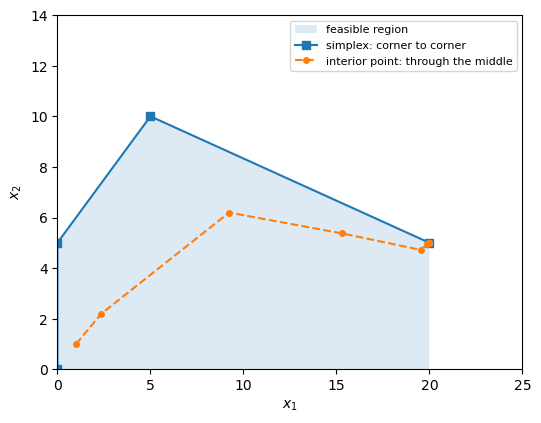

In [12]:
path = np.array(path)
fig, ax = plt.subplots(figsize=(6, 4.6))
ax.fill(corners[:, 0], corners[:, 1], alpha=0.15, label="feasible region")
ax.plot([0, 0, 5, 20], [0, 5, 10, 5], "s-", label="simplex: corner to corner")
ax.plot(path[:, 0], path[:, 1], "o--", markersize=4, label="interior point: through the middle")
ax.set(xlim=(0, 25), ylim=(0, 14), xlabel="$x_1$", ylabel="$x_2$")
ax.legend(loc="upper right", fontsize=8)
plt.show()
# alt: Simplex goes from (0,0) up to (0,5), to (5,10), then down to (20,5) along the region's edges; the interior-point path starts at (1,1) inside the region and curves through the middle, arriving at (20,5) from inside.

## Method 4: Gurobi

The same model in GurobiPy. **Predict the objective value before you run it.**

In [13]:
m = gp.Model("lp")
xv = m.addVars(2, name="x")
m.setObjective(2 * xv[0] + 3 * xv[1], GRB.MAXIMIZE)
m.addConstr(-xv[0] + xv[1] <= 5, name="c1")
m.addConstr(xv[0] + 3 * xv[1] <= 35, name="c2")
m.addConstr(xv[0] <= 20, name="c3")
m.Params.OutputFlag = 0
m.optimize()
print("z =", m.ObjVal, "| x =", [v.X for v in xv.values()])

Restricted license - for non-production use only - expires 2027-11-29


z = 55.0 | x = [20.0, 5.0]


Gurobi has the same three families you just met. The `Method` parameter picks one: 0 is primal
simplex, 1 is dual simplex, 2 is barrier (interior point). **That one parameter is the only thing
that changes in this loop.** Which do you expect to take the fewest iterations? Presolve is switched
off so the counts are the algorithms' own, not what is left after Gurobi has simplified the model.

In [14]:
m.Params.Presolve = 0
for method, name in [(0, "primal simplex"), (1, "dual simplex"), (2, "barrier")]:
    m.reset()
    m.Params.Method = method
    m.Params.Crossover = 0
    m.optimize()
    print(f"{name:15s} z = {m.ObjVal:6.2f}  simplex iterations = {m.IterCount:.0f}  barrier iterations = {m.BarIterCount}")

primal simplex  z =  55.00  simplex iterations = 3  barrier iterations = 0
dual simplex    z =  55.00  simplex iterations = 2  barrier iterations = 0
barrier         z =  55.00  simplex iterations = 0  barrier iterations = 5


## The prices behind the answer

Each constraint has a dual value (`Pi`): how much $z$ would rise per unit of extra right-hand side.

In [15]:
m.reset()
m.Params.Method = -1      # back to Gurobi's default choice
m.Params.Crossover = -1
m.optimize()
for con in m.getConstrs():
    print(f"{con.ConstrName}: dual = {con.Pi:.4f}, slack = {con.Slack:g}")

c1: dual = 0.0000, slack = 20
c2: dual = 1.0000, slack = 0
c3: dual = 1.0000, slack = 0


Compare these with the numbers under $s_1, s_2, s_3$ in row $z$ of your final tableau.

- Why does the constraint with slack left over have a dual of zero?
- Raise the 20 in $x_1 \le 20$ to 21. Predict the new $z$ from the duals, then re-solve to check.
  How far can you raise it before the prediction stops working, and which corner of the graph tells you?